# Does adding calendar and prior-year weather data improve the forecast with a 28-day lookback window?

在这个notebook里将近期天气回看窗口固定为预测目标日期前连续最近28天的数据输入；对比模型在加入previous year同期数据和calendar位置后的变化；

| Input setting | Information for one target date | Columns |
|---|---|---:|
| 28-day lookback | 28 consecutive days before the target date × 19 weather fields | 532 |
| Calendar only | Sine and cosine of the target date’s annual phase | 2 |
| Recent + calendar | Recent weather and calendar pair for each recent day and target | 590 |
| History + calendar | 7 days around the same date in each of 5 previous years, with calendar pairs, plus target calendar | 737 |
| Recent + history + calendar | Both weather windows, all historical dates’ calendar pairs and the target calendar | 1,325 |

例如：For a January 1, 2025 forecast, the 28-day lookback window covers December 4–31, 2024. For the nearest historical window, the January 1, 2024 anchor yields December 29, 2023 through January 4, 2024. February 29 uses February 28 in non-leap anchor years. Source-day highs, lows and weather codes always precede the target. The common baseline always uses only daily mean temperatures from the 28 consecutive days before the target date.

### Results for every model

Mean validation RMSE in °C, averaged over five chronological folds. Smaller is better. The last column shows the change when five prior-year windows are added to recent weather and calendar inputs. A negative value means the added history reduced error.

| Model | 28-day lookback | Calendar only | Recent + calendar | History + calendar | All inputs | Change from adding history |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 3.206 | 3.206 | 3.206 | 3.206 | 3.206 | +0.000 |
| LinearRegression | 3.840 | 4.153 | 4.268 | 12.282 | 17.582 | +13.313 |
| Ridge | 3.661 | 4.153 | 3.778 | 7.580 | 5.025 | +1.247 |
| KNN | 4.241 | 4.632 | 4.200 | 4.581 | 4.383 | +0.184 |
| Lasso | 3.055 | 4.153 | 3.055 | 5.435 | 3.605 | +0.551 |
| ElasticNet | 3.144 | 4.153 | 3.146 | 5.636 | 3.883 | +0.738 |
| SVR | 3.279 | 4.172 | 3.334 | 5.240 | 3.687 | +0.353 |
| NN | 3.426 | 4.185 | 3.423 | 4.890 | 3.887 | +0.465 |
| RandomForest | 2.927 | 4.594 | 2.922 | 4.432 | 2.986 | +0.063 |
| Poly | 4.454 | 4.169 | 4.477 | 5.108 | 4.360 | -0.117 |
| Poly Ridge | 4.298 | 5.525 | 4.332 | 5.067 | 4.255 | -0.077 |
| Poly Lasso | 2.814 | 4.165 | 2.817 | 4.641 | 2.904 | +0.087 |

Lowest measured validation error: **Poly Lasso**, **28-day lookback**, **2.814°C**.

In [1]:
from pathlib import Path
import sys

# Launch from the project root or this subfolder.
here = Path.cwd()
if not (here / "experiments.py").exists():
    here = here / "regression_inputs"
sys.path.insert(0, str(here.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from experiments import Inputs, MODELS, LINEAR, SETTINGS, evaluate, summarize

# Saved scores refer to this exact weather file.
from hashlib import sha256
from experiments import DATA
if sha256(DATA.read_bytes()).hexdigest() != "e1ac9e85c904d3b35bfcc4ee3bb30d8e8e47a7f78d76454ebcc5b9586dd71ea5":
    print("Weather CSV changed. Refit every model before comparing with the saved scores.")

part = 2
study = Inputs(part)
# False displays the committed measurements. True runs every missing fold.
RUN_FULL = False
# Limit this list to one family for a smaller new run.
MODELS_TO_FIT = MODELS.copy()
RUN_SELECTED_TEST = False
print("All model entries:", ", ".join(MODELS))
print(f"{len(study.dates):,} targets, {study.dates[0].date()} through {study.dates[-1].date()}")
print("First test date:", study.test_start.date())

All model entries: Baseline, LinearRegression, Ridge, KNN, Lasso, ElasticNet, SVR, NN, RandomForest, Poly, Poly Ridge, Poly Lasso
5,112 targets, 2011-01-04 through 2025-01-01
First test date: 2021-03-17


### Check the calendar alignment

Each seven-day historical window belongs to an earlier year. The first dates can fall in December when the target is in early January.

In [2]:
example = study.dates.get_loc("2025-01-01")
windows = [[i + 1, study.history[7*i][example].date(), study.history[7*i + 6][example].date()]
           for i in range(5)]
display(pd.DataFrame(windows, columns=["Years earlier", "Window start", "Window end"]))
assert windows[0][1] == pd.Timestamp("2023-12-29").date()
assert windows[0][2] == pd.Timestamp("2024-01-04").date()
assert study.history[-1][example] < study.dates[example]
assert study.test_start == pd.Timestamp("2021-03-17")

,Years earlier,Window start,Window end
0,1,2023-12-29,2024-01-04
1,2,2022-12-29,2023-01-04
2,3,2021-12-29,2022-01-04
3,4,2020-12-29,2021-01-04
4,5,2019-12-29,2020-01-04


### Which dates train and validate each model?

In [3]:
splits = []
for fold, (train, valid) in enumerate(study.splits(), start=1):
    splits.append([fold, len(train), study.dates[train[0]].date(), study.dates[train[-1]].date(),
                   len(valid), study.dates[valid[0]].date(), study.dates[valid[-1]].date()])
display(pd.DataFrame(splits, columns=["Fold", "Train days", "Train start", "Train end",
                                      "Validation days", "Validation start", "Validation end"]))

,Fold,Train days,Train start,Train end,Validation days,Validation start,Validation end
0,1,625,2011-01-04,2012-09-19,620,2012-09-20,2014-06-01
1,2,1245,2011-01-04,2014-06-01,620,2014-06-02,2016-02-11
2,3,1865,2011-01-04,2016-02-11,620,2016-02-12,2017-10-23
3,4,2485,2011-01-04,2017-10-23,620,2017-10-24,2019-07-05
4,5,3105,2011-01-04,2019-07-05,620,2019-07-06,2021-03-16


### Model and scoring conventions

依旧使用main.ipynb中相同的模型lineup和参数；

In [4]:
saved = pd.read_csv(here / "validation_folds.csv")
scores = saved.loc[saved.part.eq(part)].copy()
if part == 1:
    scores["setting"] = scores.setting.astype(int)
if RUN_FULL:
    fresh_rows = []
    for setting in study.settings:
        print(f"Evaluating {setting} ...", flush=True)
        for model in MODELS_TO_FIT:
            fresh_rows.append(evaluate(study, [model], [setting]))
            print(f"  {model} complete", flush=True)
    fresh = pd.concat(fresh_rows, ignore_index=True)
    scores = pd.concat([scores.loc[~scores.model.isin(MODELS_TO_FIT)], fresh], ignore_index=True)

summary = summarize(scores)
assert summary.folds.eq(5).all()
# Only complete five-fold comparisons enter this table.
errors = summary.pivot(index="setting", columns="model", values="cv_rmse").reindex(
    index=study.settings, columns=MODELS)
print(f"{int(errors.notna().sum().sum())} of {errors.size} setting/model pairs scored.")
print("Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.")
display(errors.map(lambda value: "—" if pd.isna(value) else f"{value:.3f}"))
warnings_seen = summary.loc[summary.convergence_warning, ["model", "setting"]]
if len(warnings_seen):
    print("Inspect convergence warnings before interpreting:", warnings_seen.values.tolist())

60 of 60 setting/model pairs scored.
Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.
Inspect convergence warnings before interpreting: [['NN', 'Calendar only'], ['ElasticNet', 'History + calendar'], ['ElasticNet', 'Recent + calendar'], ['ElasticNet', 'Recent + history + calendar'], ['ElasticNet', 'Recent 28'], ['Poly Lasso', 'Recent 28'], ['Poly Lasso', 'Recent + calendar'], ['Poly Lasso', 'History + calendar'], ['Poly Lasso', 'Recent + history + calendar']]


model,Baseline,LinearRegression,Ridge,KNN,Lasso,ElasticNet,SVR,NN,RandomForest,Poly,Poly Ridge,Poly Lasso
setting,,,,,,,,,,,,
Recent 28,3.206,3.840,3.661,4.241,3.055,3.144,3.279,3.426,2.927,4.454,4.298,2.814
Calendar only,3.206,4.153,4.153,4.632,4.153,4.153,4.172,4.185,4.594,4.169,5.525,4.165
Recent + calendar,3.206,4.268,3.778,4.200,3.055,3.146,3.334,3.423,2.922,4.477,4.332,2.817
History + calendar,3.206,12.282,7.580,4.581,5.435,5.636,5.240,4.890,4.432,5.108,5.067,4.641
Recent + history + calendar,3.206,17.582,5.025,4.383,3.605,3.883,3.687,3.887,2.986,4.360,4.255,2.904


### How do the five input settings compare?

Each panel shows the five settings for one model. The vertical scale can differ by panel. Use the table above for exact cross-model comparisons. The paired differences below compare forecasts from the same validation dates.

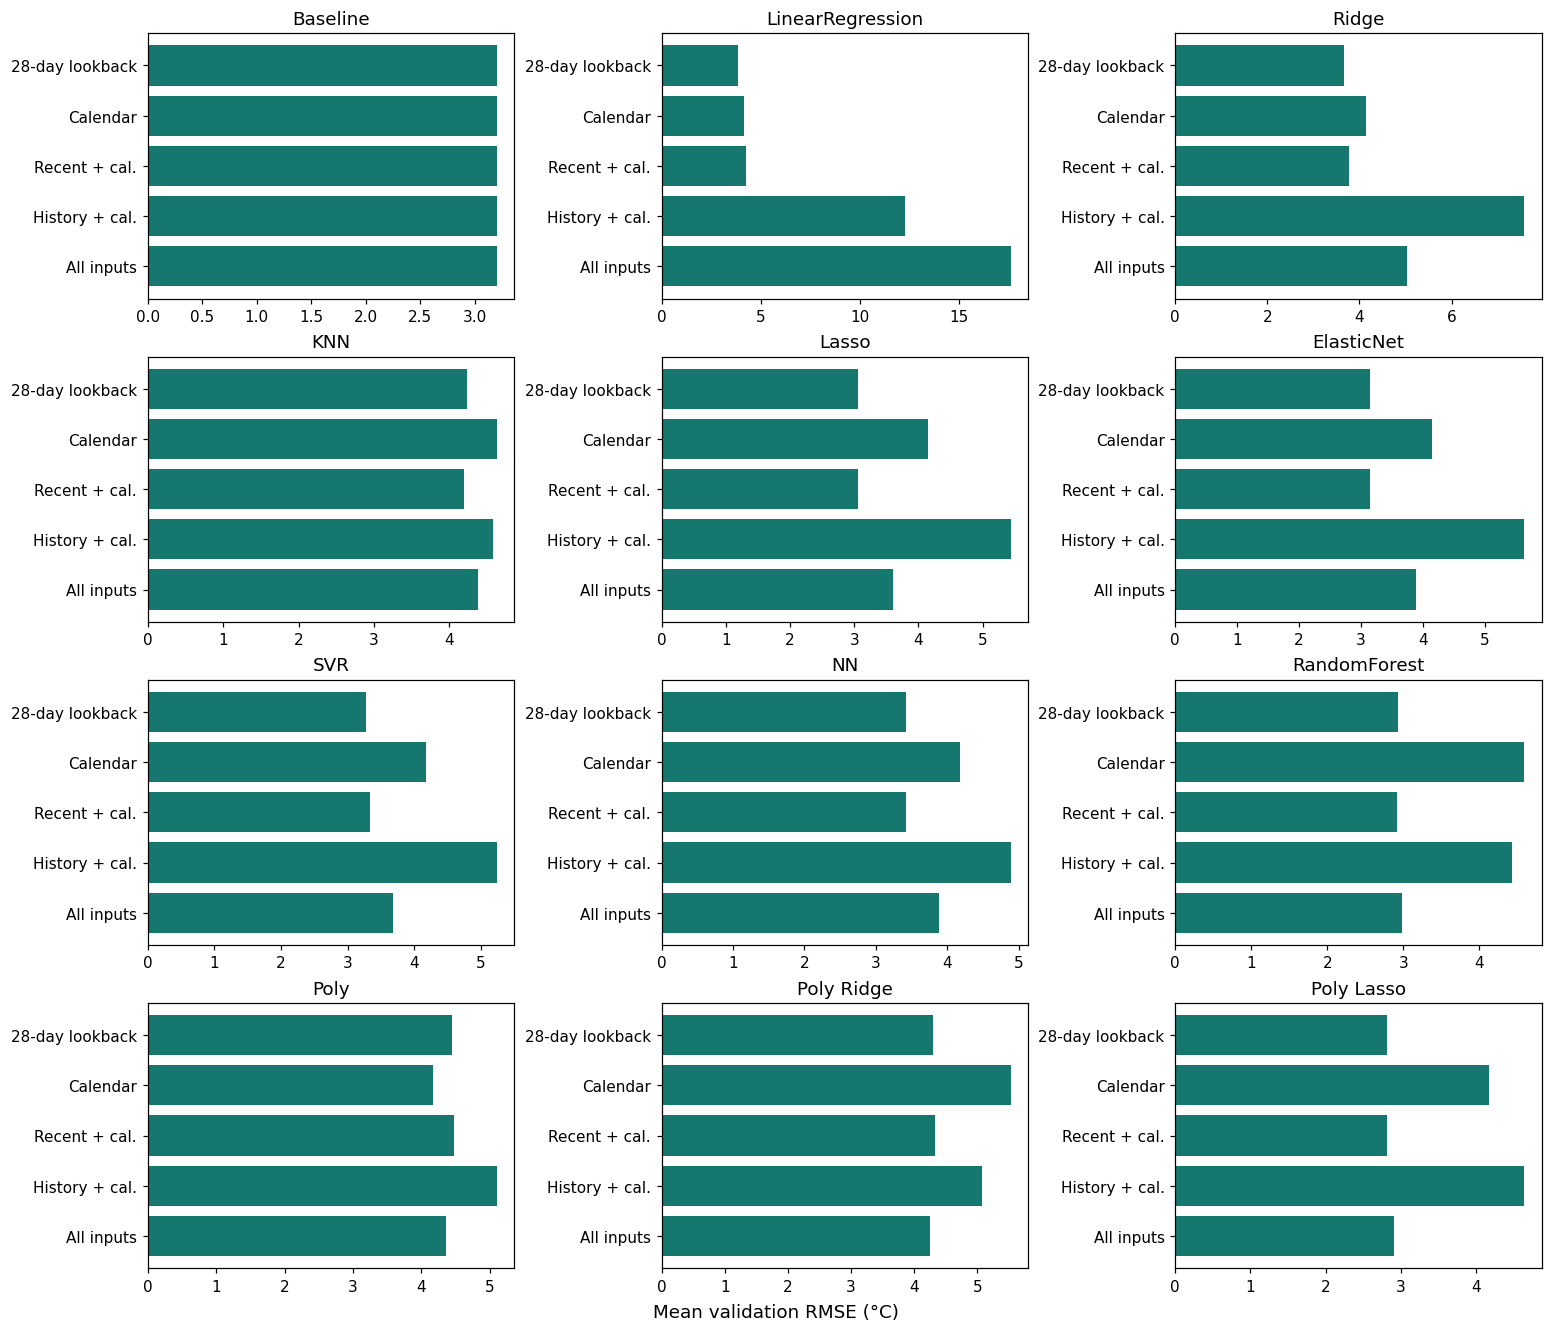

,Add calendar to recent,Add history to recent + calendar,Add recent to history + calendar
model,,,
Baseline,0.000,0.000,0.000
ElasticNet,0.001,0.738,-1.753
KNN,-0.041,0.184,-0.197
Lasso,-0.001,0.551,-1.830
LinearRegression,0.428,13.313,5.300
NN,-0.004,0.465,-1.002
Poly,0.023,-0.117,-0.748
Poly Lasso,0.003,0.087,-1.737
Poly Ridge,0.034,-0.077,-0.812


,Add calendar to recent,Add history to recent + calendar,Add recent to history + calendar
fold,,,
1,0.335,-0.495,-10.623
2,0.113,4.190,1.158
3,0.069,1.249,-0.743
4,0.053,0.786,-1.393
5,0.013,0.507,-1.174


In [5]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12), constrained_layout=True)
labels = ["28-day lookback", "Calendar", "Recent + cal.", "History + cal.", "All inputs"]
for ax, model in zip(axes.flat, MODELS):
    ax.barh(labels, errors.loc[SETTINGS, model], color="#16776f")
    ax.invert_yaxis()
    ax.set_title(model)
fig.supxlabel("Mean validation RMSE (°C)")
plt.show()

paired = scores.pivot(index=["model", "fold"], columns="setting", values="rmse")
delta = pd.DataFrame({
    "Add calendar to recent": paired["Recent + calendar"] - paired["Recent 28"],
    "Add history to recent + calendar": paired[SETTINGS[-1]] - paired["Recent + calendar"],
    "Add recent to history + calendar": paired[SETTINGS[-1]] - paired["History + calendar"]})
display(delta.groupby(level="model").mean().dropna(how="all").round(3))
display(delta.xs("Ridge").round(3))

### What the full comparison shows

With Bill’s fixed Ridge penalty, recent weather plus calendar scored **3.778°C**. Adding five years of seasonal windows increased mean validation RMSE to **5.025°C**. For KNN the same comparison moved from **4.200°C** to **4.383°C**. The full design has **1,325 inputs**, and the earliest fold has only **625 training days**. Bill selected a very small Ridge penalty for his 133-input experiment. Stronger regularization or another model could give a different result.

The unregularized quadratic model is a counterexample. Its RMSE decreased from **4.477°C** to **4.360°C** with the prior-year windows, although both values exceeded the **3.206°C** temperature-only baseline. Distinguish “helps this model” from “beats the baseline.”

Adding prior-year windows to recent weather and calendar features lowered mean validation RMSE for 2 of the 11 all-weather model variants. Bill’s temperature-only baseline uses the same daily mean temperatures from the 28-day lookback window in every column.

### Final score on the reserved dates

In [6]:
if RUN_SELECTED_TEST:
    if errors.isna().any().any():
        raise ValueError("Complete the comparison with RUN_FULL=True before selecting by validation.")
    # Each model's input design is selected on validation only.
    selected = {model: errors[model].idxmin() for model in MODELS}
    held = pd.concat([evaluate(study, [model], [setting], test=True)
                      for model, setting in selected.items()], ignore_index=True)
    display(held.groupby(["model", "setting"]).agg(test_rmse=("rmse", "mean"),
            mae=("mae", "mean"), seeds=("seed", "nunique")).round(3))
else:
    print("Holdout scoring is off. Validation determines the preferred inputs.")

Holdout scoring is off. Validation determines the preferred inputs.
